In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python executable: ~/.venvs/olist-env/bin/python
Pandas version: 3.0.6
NumPy version: 2.5.4


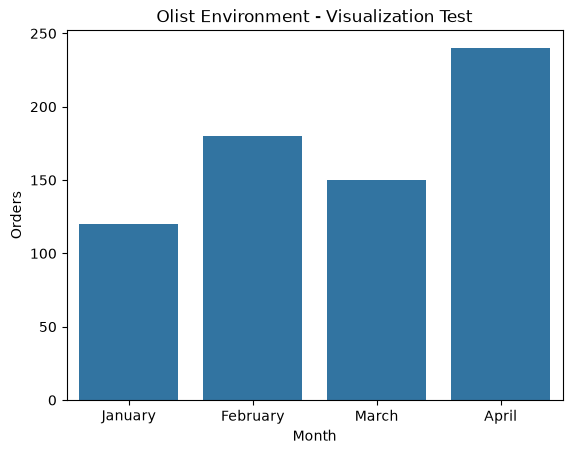

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sample_data = pd.DataFrame({
    "month": ["January", "February", "March", "April"],
    "orders": [120, 180, 150, 240]
})

sns.barplot(
    data=sample_data,
    x="month",
    y="orders"
)

plt.title("Olist Environment - Visualization Test")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.show()

### Python Environment Requirements

Use the existing **Python (Olist Data Engineering)** kernel.

Required analysis packages include Pandas, NumPy, Matplotlib, and Seaborn.

Verify dependencies in the project environment before executing the notebook. Avoid installing packages automatically during analysis.


In [3]:
# 1. Your final environment architecture

WINDOWS
   |
   v
WSL 2 - UBUNTU
   |
   +-- Jupyter Classic Server
   |       |
   |       +-- Port 8890
   |       |
   |       +-- Python (Olist Data Engineering)
   |               |
   |               +-- olist-env
   |               |
   |               +-- Pandas 3.0.6
   |               +-- NumPy 2.5.4
   |               +-- Matplotlib
   |               +-- Seaborn
   |               +-- SQLAlchemy
   |               +-- PostgreSQL Driver
   |
   +-- Kaggle CLI Environment
   |       |
   |       +-- Kaggle Authentication
   |       +-- Dataset Download
   |
   +-- projects/olist_ecommerce/
           |
           +-- data/raw/
           |      |
           |      +-- Nine Olist CSV files
           |
           +-- notebooks/
           +-- src/
           +-- reports/
           +-- logs/

In [4]:
# The other libraries shown are part of our intended setup; we will verify them individually as we use them.

# 2. Resume Phase 2 — Lesson 2: Loading Olist Data into Pandas

We can now return to the lesson without skipping anything.

Keep your Olist Jupyter notebook open.

# Practical Lab 1 — Verify the dataset directory

In [5]:
from pathlib import Path
import pandas as pd

# Locate the portfolio repository from the notebook working directory.
working_directory = Path.cwd().resolve()

candidates = [
    working_directory,
    working_directory.parent,
]

portfolio_root = next(
    (
        path for path in candidates
        if (path / "notebooks").is_dir()
        and (path / "reports").is_dir()
    ),
    None
)

if portfolio_root is None:
    raise FileNotFoundError(
        "Open Jupyter from the portfolio repository or its notebooks directory."
    )

# Load datasets from the repository-relative data directory.
# Download the nine Olist CSV files separately; do not commit them.
DATA_DIR = portfolio_root / "data" / "raw"

required_files = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

missing_files = [
    filename
    for filename in required_files
    if not (DATA_DIR / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing Olist CSV files in data/raw/: "
        + ", ".join(missing_files)
        + ". Download the dataset from Kaggle and extract all nine CSV files."
    )

PROJECT_ROOT = portfolio_root

print("Portfolio root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("CSV files found:", len(list(DATA_DIR.glob("*.csv"))))


Portfolio root: ~/projects/olist-ecommerce-analysis
Dataset directory: ~/projects/olist-ecommerce-analysis/data/raw
CSV files found: 9


In [6]:
# Practical Lab 2 — Load the orders dataset

In [7]:
orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv"
)

print("Orders dataset dimensions:", orders.shape)

display(orders.head())

Orders dataset dimensions: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
print("=" * 55)
print("OLIST ORDERS — INITIAL VALIDATION")
print("=" * 55)

print("Total rows:", len(orders))
print("Total columns:", len(orders.columns))
print("Missing order IDs:", orders["order_id"].isna().sum())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

assert orders.shape == (99441, 8)
assert orders["order_id"].notna().all()
assert orders["order_id"].is_unique

print("\nORDERS DATASET VALIDATION: PASS")

OLIST ORDERS — INITIAL VALIDATION
Total rows: 99441
Total columns: 8
Missing order IDs: 0
Duplicate order IDs: 0

ORDERS DATASET VALIDATION: PASS


In [9]:
# For the standard Olist dataset, the expected shape is:

Orders dataset dimensions: (99441, 8)

The first number represents the rows. The second represents the columns.

In [10]:
# Practical Lab 3 — Inspect the structure

In [11]:
print("Column names:")
print(orders.columns.tolist())

print("\nColumn data types:")
print(orders.dtypes)

print("\nDataFrame information:")
orders.info()

Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Column data types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  st

In [12]:
# This will help us understand how Pandas represents the original CSV contents.

In [13]:
# Practical Lab 4 — Check missing values

In [14]:
missing_values = orders.isna().sum()

print("Missing values by column:")
print(missing_values)

Missing values by column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [15]:
# For a more informative report:

In [16]:
missing_report = pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_percentage": (
        orders.isna().mean() * 100
    ).round(2)
})

display(missing_report)

,missing_count,missing_percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


This introduces our first real data-quality analysis.

In [17]:
# Practical Lab 5 — Verify the visualization libraries

# Execute this test using synthetic values:

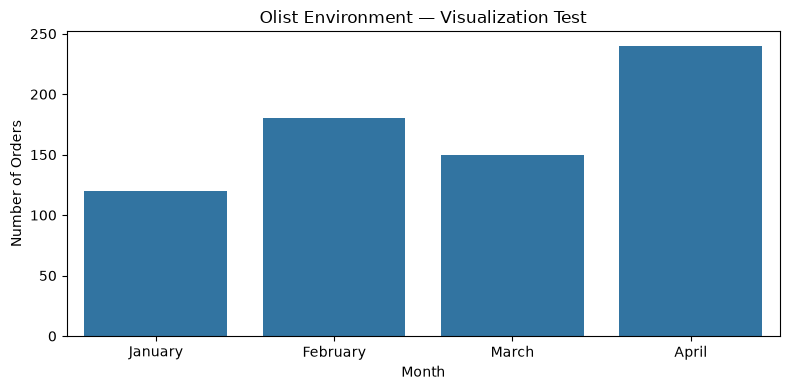

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

test_data = pd.DataFrame({
    "Month": ["January", "February", "March", "April"],
    "Orders": [120, 180, 150, 240]
})

plt.figure(figsize=(8, 4))

sns.barplot(
    data=test_data,
    x="Month",
    y="Orders"
)

plt.title("Olist Environment — Visualization Test")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [19]:
# This tests whether Matplotlib and Seaborn can render a chart inside your dedicated Jupyter kernel. The values are 

# illustrative, not Olist records.

# Our current progress

Phase 1 — Development environment

Phase 2, Lesson 1 — Acquisition and initial CSV validation

Olist virtual environment and kernel registration

Phase 2, Lesson 2 — Pandas loading and exploration

Phase 2, Lesson 3 — Comprehensive data profiling


Next checkpoint: Execute the five practical labs in your existing Jupyter Classic notebook, beginning with CSV discovery
and loading the orders table.

Share the orders.shape, missing-values report, and whether the visualization appeared correctly. We will then continue 
systematically through all nine Olist tables, preserving the full foundational explanations and using ASCII diagrams
throughout the course.

In [20]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sqlalchemy
import psycopg
import pyarrow

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("SQLAlchemy:", sqlalchemy.__version__)
print("Psycopg:", psycopg.__version__)
print("Psycopg implementation:", psycopg.pq.__impl__)
print("PyArrow:", pyarrow.__version__)

print("\nOLIST ENVIRONMENT: PASS")

Python: ~/.venvs/olist-env/bin/python
Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
SQLAlchemy: 2.1.4
Psycopg: 3.3.6
Psycopg implementation: binary
PyArrow: 26.0.0

OLIST ENVIRONMENT: PASS


In [21]:
# Practical Lab 6 — Convert timestamps

# To preserve the original DataFrame, create a working copy:

In [22]:
orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

print(orders_clean.dtypes)

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


# Expected data types for the five timestamp columns:

`datetime64[ns]` — example Pandas datetime data type.


errors="coerce" converts values that cannot be interpreted as dates into NaT, Pandas' missing datetime marker.

We should therefore verify that the conversion did not create additional missing values:

In [23]:
comparison = pd.DataFrame({
    "missing_before": orders[date_columns].isna().sum(),
    "missing_after": orders_clean[date_columns].isna().sum()
})

comparison["new_missing"] = (
    comparison["missing_after"]
    - comparison["missing_before"]
)

display(comparison)

,missing_before,missing_after,new_missing
order_purchase_timestamp,0,0,0
order_approved_at,160,160,0
order_delivered_carrier_date,1783,1783,0
order_delivered_customer_date,2965,2965,0
order_estimated_delivery_date,0,0,0


In [24]:
# Ideally, new_missing will be zero for every column.

Your missing-values report is particularly useful.

| Column                          | Missing records | Missing % |
| ------------------------------- | --------------- | --------- |
| `order_id`                      | 0               | 0.00%     |
| `customer_id`                   | 0               | 0.00%     |
| `order_status`                  | 0               | 0.00%     |
| `order_purchase_timestamp`      | 0               | 0.00%     |
| `order_approved_at`             | 160             | 0.16%     |
| `order_delivered_carrier_date`  | 1,783           | 1.79%     |
| `order_delivered_customer_date` | 2,965           | 2.98%     |
| `order_estimated_delivery_date` | 0               | 0.00%     |

Missing-value percentage by column

0%0.8%1.6%2.4%3.2%Delivered to custom…Delivered to carrierOrder approvedOther five columns

Percentages are based on 99,441 orders.

The most important observation is that 2,965 orders have no recorded customer-delivery date.

However, that does not automatically mean those records are erroneous.

Some orders could have been canceled, remained in transit, or never reached a delivered state.

Before removing or replacing missing values, we must examine the business context.

In [25]:
# 5. Practical Lab 7 — Analyze order statuses

# Run this in your Olist Jupyter notebook:

In [26]:
status_counts = orders_clean[
    "order_status"
].value_counts()

display(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [27]:
# This counts how many orders belong to each status.

In [28]:
# Now calculate percentages:

In [29]:
status_percentages = (
    orders_clean["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(status_percentages)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

What does normalize=True do?

Without normalization, value_counts() returns counts.

With normalization, it returns proportions between zero and one.

Multiplying by 100 converts those proportions into percentages.

In [30]:
# 6. Practical Lab 8 — Missing delivery dates by order status

# This is an important real-world data-quality investigation.

We are asking:
    
Which order statuses account for the missing customer-delivery dates?

This helps distinguish potentially legitimate missing values from records requiring investigation.

We should not automatically fill missing delivery dates with the estimated delivery date. An estimate is not evidence of
actual delivery.

In [31]:
# 7. Practical Lab 9 — Verify unique order identifiers

# An order ID should uniquely identify an order in the orders table.

In [32]:
print("Total rows:", len(orders_clean))

print(
    "Unique order IDs:",
    orders_clean["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    orders_clean["order_id"].duplicated().sum()
)

print(
    "Missing order IDs:",
    orders_clean["order_id"].isna().sum()
)

Total rows: 99441
Unique order IDs: 99441
Duplicate order IDs: 0
Missing order IDs: 0


In [33]:
# For a valid primary-key candidate, we want:

Missing order IDs: 0
Duplicate order IDs: 0

Your previous output already established zero missing order IDs. We still need to verify uniqueness.

## 8. Practical Lab 10 — Test actual Olist order-status visualization

Once the status counts have been calculated, run:

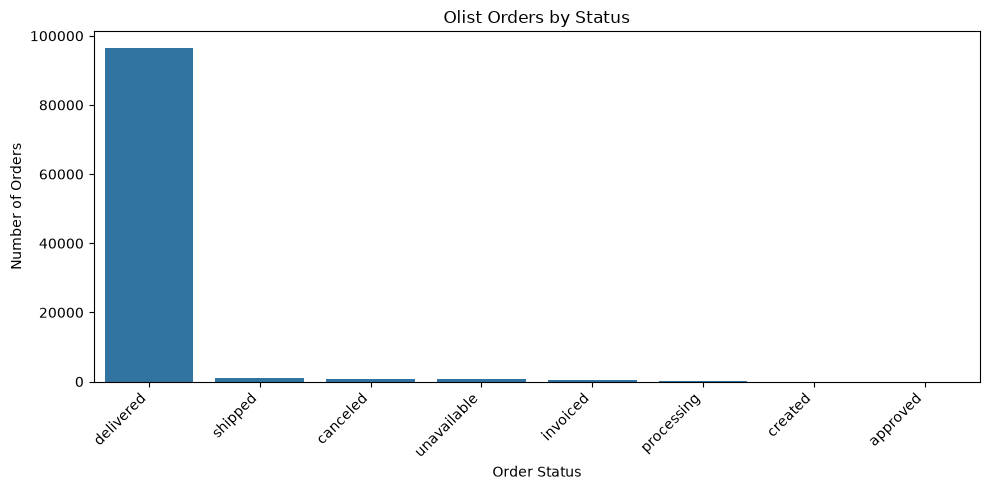

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

status_df = (
    orders_clean["order_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="order_count")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=status_df,
    x="status",
    y="order_count"
)

plt.title("Olist Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This is our first visualization using real Olist data, rather than synthetic test records.

Your preference for ASCII diagrams will continue to apply to architecture diagrams, relationships, process flows, and
educational illustrations. Matplotlib and Seaborn remain appropriate for the actual statistical charts produced in the 
data-analysis labs

## Part 3: Validation Results and Completing the Orders Dataset Investigation

In [35]:
## 3. Practical Lab 8 — Missing delivery dates by order status

In [36]:
delivery_missing_by_status = (
    orders_clean.groupby("order_status")[
        "order_delivered_customer_date"
    ]
    .agg(
        total_orders="size",
        missing_delivery_dates=lambda col: col.isna().sum()
    )
)

delivery_missing_by_status["missing_percentage"] = (
    100
    * delivery_missing_by_status["missing_delivery_dates"]
    / delivery_missing_by_status["total_orders"]
).round(2)

display(delivery_missing_by_status)

,total_orders,missing_delivery_dates,missing_percentage
order_status,,,
approved,2,2,100.00
canceled,625,619,99.04
created,5,5,100.00
delivered,96478,8,0.01
invoiced,314,314,100.00
processing,301,301,100.00
shipped,1107,1107,100.00
unavailable,609,609,100.00


In [37]:
## 5. Practical Lab 10 — Visualize the actual order statuses

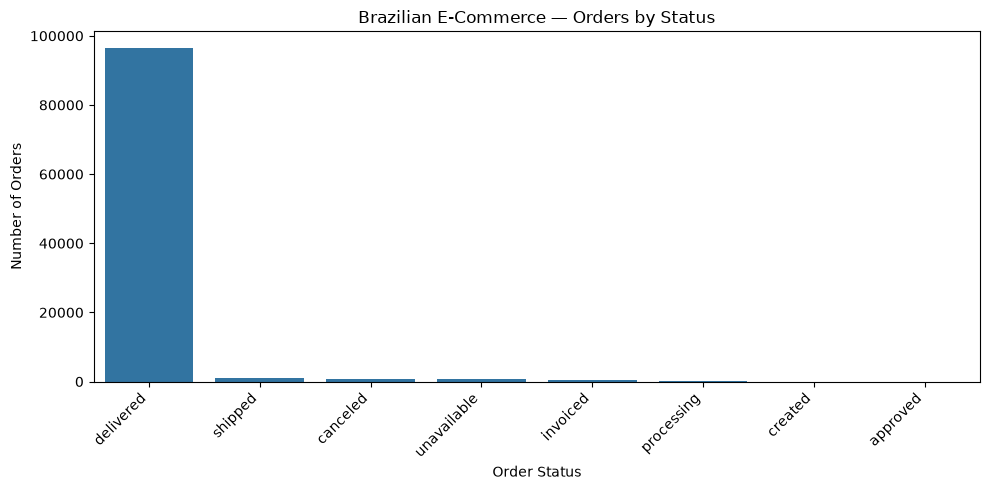

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

status_df = (
    orders_clean["order_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="order_count")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=status_df,
    x="status",
    y="order_count"
)

plt.title("Brazilian E-Commerce — Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [39]:
## 6. Practical Lab 11 — Load all nine Olist datasets

In [40]:
file_map = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv",
}

tables = {}

for name, filename in file_map.items():
    path = DATA_DIR / filename

    tables[name] = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    print(
        f"{name:15s} "
        f"Rows: {len(tables[name]):>10,} "
        f"Columns: {len(tables[name].columns):>3}"
    )

customers       Rows:     99,441 Columns:   5


geolocation     Rows:  1,000,163 Columns:   5
order_items     Rows:    112,650 Columns:   7


payments        Rows:    103,886 Columns:   5


reviews         Rows:     99,224 Columns:   7


orders          Rows:     99,441 Columns:   8
products        Rows:     32,951 Columns:   9
sellers         Rows:      3,095 Columns:   4
categories      Rows:         71 Columns:   2


In [41]:
print("=" * 60)
print("OLIST FINANCIAL INPUT VALIDATION")
print("=" * 60)

required_columns = {
    "orders": ["order_id", "order_status"],
    "order_items": [
        "order_id",
        "order_item_id",
        "price",
        "freight_value",
    ],
    "payments": [
        "order_id",
        "payment_sequential",
        "payment_value",
    ],
}

for table_name, columns in required_columns.items():
    df = tables[table_name]

    missing = [
        column for column in columns
        if column not in df.columns
    ]

    assert not missing, (
        f"{table_name}: Missing required columns: {missing}"
    )

    print(f"\n{table_name.upper()}: PASS")
    print("Rows:", len(df))
    print("Required columns:", ", ".join(columns))

for table_name, columns in {
    "order_items": ["price", "freight_value"],
    "payments": ["payment_value"],
}.items():
    for column in columns:
        assert pd.api.types.is_numeric_dtype(
            tables[table_name][column]
        ), f"{table_name}.{column} is not numeric"

        print(
            f"PASS: {table_name}.{column} "
            f"is numeric"
        )

print("\nFINANCIAL INPUT VALIDATION: PASS")

OLIST FINANCIAL INPUT VALIDATION

ORDERS: PASS
Rows: 99441
Required columns: order_id, order_status

ORDER_ITEMS: PASS
Rows: 112650
Required columns: order_id, order_item_id, price, freight_value

PAYMENTS: PASS
Rows: 103886
Required columns: order_id, payment_sequential, payment_value
PASS: order_items.price is numeric
PASS: order_items.freight_value is numeric
PASS: payments.payment_value is numeric

FINANCIAL INPUT VALIDATION: PASS


In [42]:
print("=" * 60)
print("OLIST — ORDER-LEVEL FINANCIAL AGGREGATION")
print("=" * 60)

# Step 1: Use the DataFrames already loaded into memory.
items = tables["order_items"]
payments = tables["payments"]

# Step 2: Aggregate order items.
items_by_order = (
    items.groupby("order_id")
    .agg(
        item_count=("order_item_id", "size"),
        item_price_total=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)

# Step 3: Aggregate payments.
payments_by_order = (
    payments.groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum")
    )
    .reset_index()
)

# Step 4: Validate uniqueness.
assert items_by_order["order_id"].is_unique
assert payments_by_order["order_id"].is_unique

# Step 5: Validate that aggregation preserves totals.
assert abs(
    items_by_order["item_price_total"].sum()
    - items["price"].sum()
) < 0.01

assert abs(
    payments_by_order["payment_total"].sum()
    - payments["payment_value"].sum()
) < 0.01

print("\nOriginal order-item records:", len(items))
print("Aggregated item-order records:", len(items_by_order))

print("\nOriginal payment records:", len(payments))
print("Aggregated payment-order records:", len(payments_by_order))

print("\nUnique item-order IDs:",
      items_by_order["order_id"].is_unique)

print("Unique payment-order IDs:",
      payments_by_order["order_id"].is_unique)

print("\nORDER-LEVEL FINANCIAL AGGREGATION: PASS")

OLIST — ORDER-LEVEL FINANCIAL AGGREGATION

Original order-item records: 112650
Aggregated item-order records: 98666

Original payment records: 103886
Aggregated payment-order records: 99440

Unique item-order IDs: True
Unique payment-order IDs: True

ORDER-LEVEL FINANCIAL AGGREGATION: PASS


In [43]:
## 7. Practical Lab 12 — Generate the complete inventory

In [44]:
inventory = []

for name, df in tables.items():
    inventory.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

,table,rows,columns,missing_cells,duplicate_rows
0,customers,99441,5,0,0
1,geolocation,1000163,5,0,261831
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0
5,orders,99441,8,4908,0
6,products,32951,9,2448,0
7,sellers,3095,4,0,0
8,categories,71,2,0,0


In [45]:
# This inventory will become our baseline for later data-quality checks and transformations.

# You can preserve it with:

In [46]:
# Read-only inventory preview for reproducibility testing.
print("Dataset inventory preview:")
display(inventory_df.head())


Dataset inventory preview:


,table,rows,columns,missing_cells,duplicate_rows
0,customers,99441,5,0,0
1,geolocation,1000163,5,0,261831
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0


In [47]:
# Practical Lab 13 — Investigate unusual order records

In [48]:
delivered_missing = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & (orders_clean["order_delivered_customer_date"].isna())
]

print("Delivered orders without delivery date:", len(delivered_missing))

display(delivered_missing)

Delivered orders without delivery date: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [49]:
# Now inspect canceled orders with delivery timestamps:

In [50]:
canceled_delivered = orders_clean[
    (orders_clean["order_status"] == "canceled")
    & (orders_clean["order_delivered_customer_date"].notna())
]

print("Canceled orders with delivery dates:", len(canceled_delivered))

display(canceled_delivered)

Canceled orders with delivery dates: 6


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08


In [51]:
## Practical Lab 14 — Examine the duplicate structure

In [52]:
geo = tables["geolocation"]

print("Total rows:", len(geo))

print(
    "Full-row duplicates:",
    geo.duplicated().sum()
)

print(
    "Unique ZIP prefixes:",
    geo["geolocation_zip_code_prefix"].nunique()
)

print(
    "Repeated ZIP prefixes:",
    geo["geolocation_zip_code_prefix"].duplicated().sum()
)

Total rows: 1000163


Full-row duplicates: 261831
Unique ZIP prefixes: 19015
Repeated ZIP prefixes: 981148


In [53]:
# Inspect sample duplicate records:

In [54]:
duplicate_geo = geo[
    geo.duplicated(keep=False)
]

display(duplicate_geo.head(10))

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


For now, do not modify `tables["geolocation"]`.

In a later transformation phase, we may need to reduce the geolocation data to an appropriate geographical grain for
joining to customers and sellers.

# 4. Understanding missing values across tables

Your inventory identifies three tables with missing values.

| Dataset  | Missing cells | Interpretation                                     |
| -------- | ------------- | -------------------------------------------------- |
| Reviews  | 145,903       | Likely concentrated in optional review text fields |
| Orders   | 4,908         | Missing order-processing and delivery timestamps   |
| Products | 2,448         | Missing product attribute values                   |

The reviews table is particularly interesting.

A review can contain a numerical score without necessarily having a written comment.

Therefore, missing review text may be normal rather than a data-quality failure.

In [55]:
## Practical Lab 15 — Detailed missing-value profiles

In [56]:
for table_name in ["reviews", "orders", "products"]:

    df = tables[table_name]

    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": (
            df.isna().mean() * 100
        ).round(2)
    })

    print(f"\nTABLE: {table_name.upper()}")

    display(report)


TABLE: REVIEWS


,missing_count,missing_percentage
review_id,0,0.00
order_id,0,0.00
review_score,0,0.00
review_comment_title,87656,88.34
review_comment_message,58247,58.70
review_creation_date,0,0.00
review_answer_timestamp,0,0.00



TABLE: ORDERS


,missing_count,missing_percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00



TABLE: PRODUCTS


,missing_count,missing_percentage
product_id,0,0.00
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


This shows exactly which columns account for the missing cells.

It also prepares us to define appropriate cleaning rules rather than applying one rule indiscriminately to all tables.

In [57]:
# 5. Practical Lab 16 — Build an enhanced data-quality inventory

We can extend the original inventory to include missing percentages and duplicate percentages.

In [58]:
quality_inventory = []

for name, df in tables.items():

    total_cells = df.shape[0] * df.shape[1]

    missing_cells = int(df.isna().sum().sum())

    duplicates = int(df.duplicated().sum())

    quality_inventory.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": missing_cells,
        "missing_percentage": round(
            missing_cells / total_cells * 100, 2
        ) if total_cells else 0,
        "duplicate_rows": duplicates,
        "duplicate_percentage": round(
            duplicates / len(df) * 100, 2
        ) if len(df) else 0
    })

quality_df = pd.DataFrame(quality_inventory)

display(quality_df)

,table,rows,columns,missing_cells,missing_percentage,duplicate_rows,duplicate_percentage
0,customers,99441,5,0,0.00,0,0.00
1,geolocation,1000163,5,0,0.00,261831,26.18
2,order_items,112650,7,0,0.00,0,0.00
3,payments,103886,5,0,0.00,0,0.00
4,reviews,99224,7,145903,21.01,0,0.00
5,orders,99441,8,4908,0.62,0,0.00
6,products,32951,9,2448,0.83,0,0.00
7,sellers,3095,4,0,0.00,0,0.00
8,categories,71,2,0,0.00,0,0.00


This creates a reusable baseline for subsequent ETL validation.

# Save the result:

In [59]:
# Read-only quality report preview for reproducibility testing.
print("Data-quality inventory preview:")
display(quality_df.head())


Data-quality inventory preview:


,table,rows,columns,missing_cells,missing_percentage,duplicate_rows,duplicate_percentage
0,customers,99441,5,0,0.00,0,0.00
1,geolocation,1000163,5,0,0.00,261831,26.18
2,order_items,112650,7,0,0.00,0,0.00
3,payments,103886,5,0,0.00,0,0.00
4,reviews,99224,7,145903,21.01,0,0.00


## Part 5: Final Validation, Data Quality Findings, and Preparation for Lesson 3

In [60]:
# 5. Final Practical Lab — Check whether missing product attributes affect the same products

In [61]:
products = tables["products"]

attributes = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

missing_matrix = products[attributes].isna()

all_four_missing = missing_matrix.all(axis=1).sum()

any_missing = missing_matrix.any(axis=1).sum()

print("Products missing all four attributes:", all_four_missing)
print("Products missing at least one attribute:", any_missing)

display(
    products.loc[
        missing_matrix.all(axis=1),
        ["product_id"] + attributes
    ].head(10)
)

Products missing all four attributes: 610
Products missing at least one attribute: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN


### What this teaches

`isna()` identifies missing values.

`all(axis=1)` checks whether every selected column is missing in the same row.

`any(axis=1)` checks whether at least one selected column is missing.

These functions allow us to investigate patterns of missing data instead of treating every missing value independently.

## Final Results: Understanding the 610 Products With Missing Attributes

## 3. Should we delete the 610 products?

No. We should preserve them.

These products still have valid-looking `product_id` identifiers, and some may appear in customer orders.

Deleting them prematurely could cause referential-integrity problems when we connect products to order items.

A better strategy is to investigate whether they appear in transactions.

In [62]:
### Practical Lab — Check whether the 610 products were purchased

In [63]:
products = tables["products"]
order_items = tables["order_items"]

attributes = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

missing_products = products.loc[
    products[attributes].isna().all(axis=1),
    "product_id"
]

affected_items = order_items[
    order_items["product_id"].isin(missing_products)
]

print("Products with missing attributes:", len(missing_products))

print(
    "Affected products appearing in orders:",
    affected_items["product_id"].nunique()
)

print(
    "Order-item records involving these products:",
    len(affected_items)
)

print(
    "Distinct affected orders:",
    affected_items["order_id"].nunique()
)

print(
    "Total item price:",
    round(affected_items["price"].sum(), 2)
)

Products with missing attributes: 610
Affected products appearing in orders: 610
Order-item records involving these products: 1603
Distinct affected orders: 1451
Total item price: 179535.28


This will answer whether missing product metadata affects real transactions and their recorded item prices.

The price total excludes freight and is not necessarily equivalent to recognized revenue.

In [64]:
products_quality = tables["products"].copy()

attributes = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

products_quality["metadata_incomplete"] = (
    products_quality[attributes].isna().any(axis=1)
)

items_with_quality = tables["order_items"].merge(
    products_quality[
        ["product_id", "metadata_incomplete"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Original order-item rows:", len(tables["order_items"]))
print("Joined order-item rows:", len(items_with_quality))

print(
    "Unmatched product references:",
    items_with_quality["metadata_incomplete"].isna().sum()
)

print(
    "Affected order-item rows:",
    items_with_quality["metadata_incomplete"].eq(True).sum()
)

print(
    "Original item-price total:",
    round(tables["order_items"]["price"].sum(), 2)
)

print(
    "Joined item-price total:",
    round(items_with_quality["price"].sum(), 2)
)

Original order-item rows: 112650
Joined order-item rows: 112650
Unmatched product references: 0
Affected order-item rows: 1603
Original item-price total: 13591643.7
Joined item-price total: 13591643.7



The 1.32% represents the share of recorded item-price totals associated with products whose four descriptive attributes are
missing. It excludes freight and is not necessarily recognized revenue.

Deleting those products from an inner-joined analysis could therefore cause approximately R$179,535.28 in item prices to be
omitted.

## 4. Preserve this validation as part of the project

We should incorporate the join checks into our future automated ETL tests.

In [65]:
assert len(items_with_quality) == len(tables["order_items"]), (
    "FAIL: Order-item row count changed"
)

assert items_with_quality["metadata_incomplete"].isna().sum() == 0, (
    "FAIL: Unmatched product references"
)

assert items_with_quality["metadata_incomplete"].eq(True).sum() == 1603, (
    "FAIL: Unexpected affected item count"
)

assert abs(
    items_with_quality["price"].sum()
    - tables["order_items"]["price"].sum()
) < 0.01, (
    "FAIL: Item-price totals do not match"
)

print("OLIST PRODUCT JOIN VALIDATION: PASS")

OLIST PRODUCT JOIN VALIDATION: PASS


# 2. Practical Lab 1 — Verify primary-key candidates

Open your existing Olist Jupyter notebook using the Python (Olist Data Engineering) kernel.

In [66]:
primary_key_candidates = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "categories": ["product_category_name"]
}

results = []

for table_name, key_columns in primary_key_candidates.items():

    df = tables[table_name]

    null_key_rows = int(
        df[key_columns].isna().any(axis=1).sum()
    )

    duplicate_key_rows = int(
        df.duplicated(subset=key_columns).sum()
    )

    results.append({
        "table": table_name,
        "key_columns": ", ".join(key_columns),
        "total_rows": len(df),
        "null_key_rows": null_key_rows,
        "duplicate_key_rows": duplicate_key_rows,
        "key_valid": (
            null_key_rows == 0
            and duplicate_key_rows == 0
        )
    })

key_validation_df = pd.DataFrame(results)

display(key_validation_df)

,table,key_columns,total_rows,null_key_rows,duplicate_key_rows,key_valid
0,customers,customer_id,99441,0,0,True
1,orders,order_id,99441,0,0,True
2,products,product_id,32951,0,0,True
3,sellers,seller_id,3095,0,0,True
4,order_items,"order_id, order_item_id",112650,0,0,True
5,payments,"order_id, payment_sequential",103886,0,0,True
6,reviews,review_id,99224,0,814,False
7,categories,product_category_name,71,0,0,True


# 3. Practical Lab 2 — Detect orphaned foreign keys

An orphaned foreign key is a value in a child table that has no matching parent record.

For example, an order referencing a nonexistent customer would be an orphan.

# Let's check the customer relationship:

In [67]:
orders_df = tables["orders"]
customers_df = tables["customers"]

orphan_customer_mask = (
    ~orders_df["customer_id"].isin(
        customers_df["customer_id"]
    )
)

orphan_orders = orders_df.loc[orphan_customer_mask]

print("Total orders:", len(orders_df))
print("Orders referencing missing customers:", len(orphan_orders))

display(orphan_orders.head())

Total orders: 99441
Orders referencing missing customers: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


### Step 1 — Extract duplicate review IDs

In your Olist Jupyter notebook, run:

In [68]:
reviews = tables["reviews"]

duplicate_reviews = reviews[
    reviews.duplicated(
        subset=["review_id"],
        keep=False
    )
].copy()

print("Total review rows:", len(reviews))

print(
    "Rows containing repeated review IDs:",
    len(duplicate_reviews)
)

print(
    "Distinct repeated review IDs:",
    duplicate_reviews["review_id"].nunique()
)

display(
    duplicate_reviews.sort_values(
        ["review_id", "order_id"]
    ).head(20)
)

Total review rows: 99224
Rows containing repeated review IDs: 1603
Distinct repeated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


Now test the actual data:

In [69]:
review_composite_key = [
    "review_id",
    "order_id"
]

null_composite_keys = reviews[
    review_composite_key
].isna().any(axis=1).sum()

duplicate_composite_keys = reviews.duplicated(
    subset=review_composite_key
).sum()

print("Null composite keys:", null_composite_keys)
print("Duplicate composite keys:", duplicate_composite_keys)

print(
    "Composite key valid:",
    null_composite_keys == 0
    and duplicate_composite_keys == 0
)

Null composite keys: 0
Duplicate composite keys: 0
Composite key valid: True


If this passes, the composite key is a possible identifier for the source review rows.

If it fails, we will inspect repeated combinations and consider a generated `review_record_id` for our database design.

Do not delete the 814 duplicate-key occurrences; we have not established that they are erroneous.

# 4. Practical Lab 4 — Validate all major foreign-key relationships

We already validated:

```
orders.customer_id
        |
        v
customers.customer_id

Orphan references: 0
```

Now we should systematically validate the remaining relationships.

### Step 1 — Define the foreign-key checks

In [70]:
foreign_key_checks = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
    (
        "products",
        "product_category_name",
        "categories",
        "product_category_name"
    )
]

In [71]:
### Step 2 — Execute the checks

In [72]:
foreign_key_results = []

for child_table, child_key, parent_table, parent_key in foreign_key_checks:

    child = tables[child_table]
    parent = tables[parent_table]

    missing_reference = child[child_key].isna()

    unmatched_reference = (
        ~child[child_key].isin(parent[parent_key])
        & ~missing_reference
    )

    foreign_key_results.append({
        "child_table": child_table,
        "foreign_key": child_key,
        "parent_table": parent_table,
        "parent_key": parent_key,
        "child_rows": len(child),
        "null_references": int(missing_reference.sum()),
        "orphan_references": int(unmatched_reference.sum())
    })

foreign_key_df = pd.DataFrame(foreign_key_results)

display(foreign_key_df)

,child_table,foreign_key,parent_table,parent_key,child_rows,null_references,orphan_references
0,orders,customer_id,customers,customer_id,99441,0,0
1,order_items,order_id,orders,order_id,112650,0,0
2,order_items,product_id,products,product_id,112650,0,0
3,order_items,seller_id,sellers,seller_id,112650,0,0
4,payments,order_id,orders,order_id,103886,0,0
5,reviews,order_id,orders,order_id,99224,0,0
6,products,product_category_name,categories,product_category_name,32951,610,13


### Understanding the results

We distinguish two kinds of reference problems:

Null references: The child record does not contain a foreign-key value.

Orphan references: The child contains a non-null foreign-key value that cannot be found in the parent table.

For the product-category translation relationship, null categories may be expected because we previously found 610 products
missing descriptive metadata.

A null category should not automatically be classified as an orphan.

# 5. Practical Lab 5 — Confirm join cardinality

We know that each order has a unique `order_id`.

However, an order can have multiple order-item records.

Let's measure this relationship.

In [73]:
items_per_order = (
    tables["order_items"]
    .groupby("order_id")
    .size()
)

print("Orders with at least one item:", len(items_per_order))

print("Minimum items per represented order:", items_per_order.min())

print("Maximum items per represented order:", items_per_order.max())

print("Average items per represented order:", round(items_per_order.mean(), 2))

display(items_per_order.value_counts().sort_index().head(15))

Orders with at least one item: 98666
Minimum items per represented order: 1
Maximum items per represented order: 21
Average items per represented order: 1.14


1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
Name: count, dtype: int64

# Fixing `NameError: name 'tables' is not defined` in Jupyter Classic

This error is common when working with Jupyter notebooks, particularly when moving between lessons or restarting kernels.

Your Olist environment is not broken, and you do not need to reinstall Pandas or Jupyter Classic.

The problem is that Python cannot find the variable `tables` in the current notebook session.

## 1. Why this error occurred

Your error points to:

```
df = tables[table_name]
```

Earlier in Phase 2, Lesson 2, we created the dictionary `tables` to store all nine Olist DataFrames.

However, Jupyter variables exist only in the memory of the active Python kernel.

The error can occur when:

- You restart the Jupyter kernel.
- You open a new notebook for Lesson 3.
- You execute the validation cell before the dataset-loading cell.
- You use a different kernel session.

For example:

```
+-------------------------------------+
| JUPYTER CLASSIC                     |
| Python (Olist Data Engineering)     |
+-------------------------------------+
                  |
                  v
+-------------------------------------+
| ACTIVE PYTHON KERNEL                |
|                                     |
| pandas imported?                    |
| tables dictionary created?          |
+-------------------------------------+
                  |
         +--------+--------+
         |                 |
         v                 v
   tables exists     tables missing
         |                 |
         v                 v
    Code works          NameError
```

Important: Saving a notebook preserves its code and saved outputs, but restarting the kernel does not automatically restore
Python variables.

## 2. Step 1 — Check the active kernel

Inside your Jupyter notebook, run:

```
import sysprint("Python executable:", sys.executable)
```

Expected:

```
~/.venvs/olist-env/bin/python
```

You already verified this interpreter previously, so we only need to confirm that the current notebook is using it.

## 3. Step 2 — Recreate the `tables` dictionary

Open a new code cell above your primary-key validation code.

Paste this complete initialization code:

```
from pathlib import Path
import pandas as pd

# Step 1: Define the Olist project directories.

PROJECT_ROOT = Path(
    "~/projects/olist_ecommerce"
)

DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Step 2: Define the nine Olist datasets.

file_map = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv",
}

# Step 3: Load the CSV files into Pandas DataFrames.

tables = {}

for table_name, filename in file_map.items():

    file_path = DATA_DIR / filename

    tables[table_name] = pd.read_csv(
        file_path,
        encoding="utf-8-sig"
    )

    print(
        f"{table_name:15s} "
        f"Rows: {len(tables[table_name]):>10,} "
        f"Columns: {len(tables[table_name].columns):>3}"
    )

print("\nOLIST DATASET INITIALIZATION: PASS")
```

### Expected output

```
customers       Rows:     99,441 Columns:   5
geolocation     Rows:  1,000,163 Columns:   5
order_items     Rows:    112,650 Columns:   7
payments        Rows:    103,886 Columns:   5
reviews         Rows:     99,224 Columns:   7
orders          Rows:     99,441 Columns:   8
products        Rows:     32,951 Columns:   9
sellers         Rows:      3,095 Columns:   4
categories      Rows:         71 Columns:   2

OLIST DATASET INITIALIZATION: PASS
```

This recreates the missing dictionary in the current kernel.

## 4. Step 3 — Verify that `tables` exists

Run:

```
print("Variable exists:", "tables" in globals())

print("Number of datasets:", len(tables))

print("Dataset names:", list(tables.keys()))
```

Expected:

```
Variable exists: True
Number of datasets: 9
```

## 5. Step 4 — Rerun your primary-key validation

Once `tables` exists, rerun the original Lesson 3 validation:

```
primary_key_candidates = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "categories": ["product_category_name"]
}

results = []

for table_name, key_columns in primary_key_candidates.items():

    df = tables[table_name]

    null_key_rows = int(
        df[key_columns].isna().any(axis=1).sum()
    )

    duplicate_key_rows = int(
        df.duplicated(subset=key_columns).sum()
    )

    results.append({
        "table": table_name,
        "key_columns": ", ".join(key_columns),
        "total_rows": len(df),
        "null_key_rows": null_key_rows,
        "duplicate_key_rows": duplicate_key_rows,
        "key_valid": (
            null_key_rows == 0
            and duplicate_key_rows == 0
        )
    })

key_validation_df = pd.DataFrame(results)

display(key_validation_df)
```

If a candidate key fails validation, that is a meaningful dataset finding, not necessarily a problem with your code. In
particular, the reviews table may have repeated `review_id` values.

## 6. Recommended notebook organization

To avoid this issue throughout our remaining lessons, every new notebook should begin with an initialization section.

```
01_olist_data_exploration.ipynb
    |
    +-- Import libraries
    +-- Define project paths
    +-- Load CSV datasets
    +-- Explore data
    +-- Generate reports

02_olist_relational_integrity.ipynb
    |
    +-- Import libraries
    +-- Define project paths
    +-- Load required datasets
    +-- Validate primary keys
    +-- Validate foreign keys
    +-- Investigate relationships
    +-- Generate integrity reports

03_olist_data_cleaning.ipynb
    |
    +-- Import libraries
    +-- Define project paths
    +-- Load required datasets
    +-- Clean and transform data
    +-- Validate transformations
```

Later, we can create a reusable Python module, such as `src/load_olist_data.py`, to avoid repeating the CSV-loading code
in every notebook.

This will also prepare us for automated ETL pipelines and Docker integration.

## 7. Your next checkpoint

Execute these steps in order:

1. Verify your current Python interpreter.
2. Run the complete dataset-initialization cell.
3. Confirm that `tables` contains nine DataFrames.
4. Rerun the primary-key validation.

Share the resulting `key_validation_df` table. We will then identify which primary-key candidates pass, which require 
further investigation, and continue Phase 2, Lesson 3 from the ground up.

There is no need to repeat the completed Kaggle download or reinstall your Olist environment.

## 3. Step 2 — Recreate the `tables` dictionary

Open a new code cell above your primary-key validation code.

Paste this complete initialization code:

In [74]:
from pathlib import Path
import pandas as pd

# Step 1: Define the Olist project directories.

# Reuse the repository and dataset paths established in Cell 11.
if "DATA_DIR" not in globals():
    raise RuntimeError(
        "Run the notebook setup cells before loading datasets."
    )

# Step 2: Define the nine Olist datasets.

file_map = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv",
}

# Step 3: Load the CSV files into Pandas DataFrames.

tables = {}

for table_name, filename in file_map.items():

    file_path = DATA_DIR / filename

    tables[table_name] = pd.read_csv(
        file_path,
        encoding="utf-8-sig"
    )

    print(
        f"{table_name:15s} "
        f"Rows: {len(tables[table_name]):>10,} "
        f"Columns: {len(tables[table_name].columns):>3}"
    )

print("\nOLIST DATASET INITIALIZATION: PASS")

customers       Rows:     99,441 Columns:   5


geolocation     Rows:  1,000,163 Columns:   5
order_items     Rows:    112,650 Columns:   7


payments        Rows:    103,886 Columns:   5


reviews         Rows:     99,224 Columns:   7


orders          Rows:     99,441 Columns:   8
products        Rows:     32,951 Columns:   9
sellers         Rows:      3,095 Columns:   4
categories      Rows:         71 Columns:   2

OLIST DATASET INITIALIZATION: PASS


In [75]:
# This recreates the missing dictionary in the current kernel.

# 4. Step 3 — Verify that tables exists

In [76]:
print("Variable exists:", "tables" in globals())

print("Number of datasets:", len(tables))

print("Dataset names:", list(tables.keys()))

Variable exists: True
Number of datasets: 9
Dataset names: ['customers', 'geolocation', 'order_items', 'payments', 'reviews', 'orders', 'products', 'sellers', 'categories']


In [77]:
# 5. Step 4 — Rerun your primary-key validation

# Once tables exists, rerun the original Lesson 3 validation:

In [78]:
primary_key_candidates = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "categories": ["product_category_name"]
}

results = []

for table_name, key_columns in primary_key_candidates.items():

    df = tables[table_name]

    null_key_rows = int(
        df[key_columns].isna().any(axis=1).sum()
    )

    duplicate_key_rows = int(
        df.duplicated(subset=key_columns).sum()
    )

    results.append({
        "table": table_name,
        "key_columns": ", ".join(key_columns),
        "total_rows": len(df),
        "null_key_rows": null_key_rows,
        "duplicate_key_rows": duplicate_key_rows,
        "key_valid": (
            null_key_rows == 0
            and duplicate_key_rows == 0
        )
    })

key_validation_df = pd.DataFrame(results)

display(key_validation_df)

,table,key_columns,total_rows,null_key_rows,duplicate_key_rows,key_valid
0,customers,customer_id,99441,0,0,True
1,orders,order_id,99441,0,0,True
2,products,product_id,32951,0,0,True
3,sellers,seller_id,3095,0,0,True
4,order_items,"order_id, order_item_id",112650,0,0,True
5,payments,"order_id, payment_sequential",103886,0,0,True
6,reviews,review_id,99224,0,814,False
7,categories,product_category_name,71,0,0,True


In [79]:
# If a candidate key fails validation, that is a meaningful dataset finding, not necessarily a problem with your code. 

# In particular, the reviews table may have repeated review_id values.

# 3. Understanding the 13 unmatched product categories

Your foreign-key report showed:

```
Child table: products
Foreign key: product_category_name
Parent table: categories

Null references:    610
Orphan references:   13
```

These represent two distinct situations.

Situation A — Missing category (610 products): The product contains no category value.

Situation B — Unmatched category (13 products): The product contains a category value that is not present in the English
category translation table.

We should investigate the 13 records before creating a strict foreign-key constraint.

## Practical Lab 6 — Examine unmatched categories

In [80]:
products = tables["products"]
categories = tables["categories"]

unmatched_mask = (
    products["product_category_name"].notna()
    & ~products["product_category_name"].isin(
        categories["product_category_name"]
    )
)

unmatched_products = products.loc[unmatched_mask]

print("Products with unmatched categories:", len(unmatched_products))

print("\nDistinct unmatched category names:")

display(
    unmatched_products["product_category_name"]
    .value_counts()
)

display(
    unmatched_products[
        ["product_id", "product_category_name"]
    ]
)

Products with unmatched categories: 13

Distinct unmatched category names:


product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64

,product_id,product_category_name
1628,0105b5323d24fc655f73052694dbbb3a,pc_gamer
5821,6fd83eb3e0799b775e4f946bd66657c0,portateis_cozinha_e_preparadores_de_alimentos
7325,5d923ead886c44b86845f69e50520c3e,portateis_cozinha_e_preparadores_de_alimentos
7478,6727051471a0fc4a0e7737b57bff2549,pc_gamer
8819,bed164d9d628cf0593003389c535c6e0,portateis_cozinha_e_preparadores_de_alimentos
11039,1220978a08a6b29a202bc015b18250e9,portateis_cozinha_e_preparadores_de_alimentos
14266,ae62bb0f95af63d64eae5f93dddea8d3,portateis_cozinha_e_preparadores_de_alimentos
16182,1954739d84629e7323a4295812a3e0ec,portateis_cozinha_e_preparadores_de_alimentos
16930,dbe520fb381ad695a7e1f2807d20c765,pc_gamer
17800,c7a3f1a7f9eef146cc499368b578b884,portateis_cozinha_e_preparadores_de_alimentos


# Why this matters

The translation file is a lookup table. An unmatched value does not necessarily mean the product category itself is invalid.
It could simply mean that the translation table does not cover every original Portuguese category.
We should retain the original category and flag the missing translation.

In [81]:
# 4. Understanding one-to-many relationships

# Your order-item investigation found:

Orders with at least one item: 98,666
Minimum items per represented order: 1
Maximum items per represented order: 21
Average items per represented order: 1.14

# Practical Lab 7 — Examine orders without items

In [82]:
orders = tables["orders"]
order_items = tables["order_items"]

orders_without_items = orders.loc[
    ~orders["order_id"].isin(order_items["order_id"])
].copy()

print("Orders without items:", len(orders_without_items))

print("\nOrder statuses:")

display(
    orders_without_items["order_status"]
    .value_counts()
)

display(orders_without_items.head(10))

Orders without items: 775

Order statuses:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
266,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaN,NaN,2017-12-05 00:00:00
586,c272bcd21c287498b4883c7512019702,9582c5bbecc65eb568e2c1d839b5cba1,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50,NaN,NaN,2018-02-16 00:00:00
687,37553832a3a89c9b2db59701c357ca67,7607cd563696c27ede287e515812d528,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18,NaN,NaN,2017-09-05 00:00:00
737,d57e15fb07fd180f06ab3926b39edcd2,470b93b3f1cde85550fc74cd3a476c78,unavailable,2018-01-08 19:39:03,2018-01-09 07:26:08,NaN,NaN,2018-02-06 00:00:00
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaN,NaN,NaN,2018-09-12 00:00:00
1160,2f634e2cebf8c0283e7ef0989f77d217,7353b0fb8e8d9675e3a704c60ca44ebe,unavailable,2017-09-27 20:55:33,2017-09-28 01:32:50,NaN,NaN,2017-10-27 00:00:00
1579,ee0db22a8e742b752914016708470ec8,aae50600d30bf2efe013ca4c1754ded7,unavailable,2017-08-24 11:04:41,2017-08-24 11:15:11,NaN,NaN,2017-09-18 00:00:00
1801,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaN,NaN,NaN,2018-10-17 00:00:00
1826,6ad57aecbae806a7e9cc2cdb6b380711,d31dbd02ac052d662285f678f8994326,unavailable,2017-11-30 07:48:24,2017-11-30 08:14:42,NaN,NaN,2017-12-29 00:00:00
1868,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30,NaN,NaN,NaN,2017-04-10 00:00:00


# An inner join produces five rows from three orders.

This is expected because orders can have multiple items.
However, if we sum an order-level value after the join, we may accidentally count it multiple times.
For example, summing payment_value after joining directly to order items could exaggerate payment totals.
A key principle for our Olist project is to preserve the correct grain of each table.
- Orders: one row per order.
- Order items: one row per (order_id, order_item_id).
- Payments: one row per (order_id, payment_sequential).
- Reviews: one row per (review_id, order_id).
- Products: one row per product.
    
# Practical Lab 8 — Measure join behavior

In [83]:
orders_items_joined = orders.merge(
    order_items,
    on="order_id",
    how="left",
    validate="one_to_many",
    indicator=True
)

print("Original orders:", len(orders))

print("Original order items:", len(order_items))

print("Joined rows:", len(orders_items_joined))

print("\nJoin match results:")

display(
    orders_items_joined["_merge"].value_counts()
)

print(
    "Distinct order IDs after join:",
    orders_items_joined["order_id"].nunique()
)

Original orders: 99441
Original order items: 112650
Joined rows: 113425

Join match results:


_merge
both          112650
left_only        775
right_only         0
Name: count, dtype: int64

Distinct order IDs after join: 99441


## 5. Practical Lab 9 — Measure actual join fanout in Olist

We will first calculate the number of item and payment rows associated with each order.

Run in your existing Olist Jupyter notebook:

In [84]:
orders = tables["orders"]
items = tables["order_items"]
payments = tables["payments"]

item_counts = (
    items.groupby("order_id")
    .size()
    .rename("item_count")
)

payment_counts = (
    payments.groupby("order_id")
    .size()
    .rename("payment_count")
)

order_cardinality = (
    orders[["order_id"]]
    .join(item_counts, on="order_id")
    .join(payment_counts, on="order_id")
)

order_cardinality[
    ["item_count", "payment_count"]
] = (
    order_cardinality[
        ["item_count", "payment_count"]
    ]
    .fillna(0)
    .astype(int)
)

display(order_cardinality.head(10))

,order_id,item_count,payment_count
0,e481f51cbdc54678b7cc49136f2d6af7,1,3
1,53cdb2fc8bc7dce0b6741e2150273451,1,1
2,47770eb9100c2d0c44946d9cf07ec65d,1,1
3,949d5b44dbf5de918fe9c16f97b45f8a,1,1
4,ad21c59c0840e6cb83a9ceb5573f8159,1,1
5,a4591c265e18cb1dcee52889e2d8acc3,1,1
6,136cce7faa42fdb2cefd53fdc79a6098,1,1
7,6514b8ad8028c9f2cc2374ded245783f,1,1
8,76c6e866289321a7c93b82b54852dc33,1,1
9,e69bfb5eb88e0ed6a785585b27e16dbf,1,2


In [85]:
# Now identify orders having multiple items and multiple payments:

In [86]:
multiple_both = order_cardinality[
    (order_cardinality["item_count"] > 1)
    & (order_cardinality["payment_count"] > 1)
]

print(
    "Orders with multiple items and payments:",
    len(multiple_both)
)

display(multiple_both.head(10))

Orders with multiple items and payments: 275


,order_id,item_count,payment_count
481,32e4fa9bb468884309b58b9348de70c3,2,2
792,ca0400dec2c292340c373e63b1c2c597,4,2
952,92a9ef7f0a0d392c9ad0d5f44e86b4ba,3,4
1081,08bdbdeaf1626720051193300f93806e,4,2
1824,5f8e8bff26bd07b73a3ecf086de33d4a,2,3
1862,fd86c80924b4be8fb7f58c4ecc680dae,2,3
1918,68c3f2fc647e6d809af24b6ccbe84388,2,2
2000,7dc27189eb855013011423a5dcac71c3,2,2
2320,0420dbc50fc554e303e4b2d6b39063f6,3,2
2838,628287e102c84327f95402d4670434d2,2,3


# These orders are especially vulnerable to multiplication when joining order items and payments directly.

# 6. Practical Lab 10 — Calculate expected join multiplication
If one order has three item records and two payment records, a direct join creates six rows.
The number of rows for a matched order is:
\[
\text{Joined rows} = \text{Item rows} \times \text{Payment rows}
\]

# For a left join beginning with orders, missing sides contribute one placeholder row each. Therefore:

In [87]:
expected_rows = (
    order_cardinality["item_count"].clip(lower=1)
    * order_cardinality["payment_count"].clip(lower=1)
).sum()

print(
    "Expected rows after joining orders, items, payments:",
    expected_rows
)

Expected rows after joining orders, items, payments: 118434


In [88]:
# Next, verify this prediction using Pandas:

In [89]:
joined = (
    orders[["order_id"]]
    .merge(
        items[["order_id", "order_item_id", "price"]],
        on="order_id",
        how="left",
        validate="one_to_many"
    )
    .merge(
        payments[
            ["order_id", "payment_sequential", "payment_value"]
        ],
        on="order_id",
        how="left"
    )
)

print("Actual joined rows:", len(joined))
print("Expected joined rows:", expected_rows)

assert len(joined) == expected_rows

print("JOIN CARDINALITY PREDICTION: PASS")

Actual joined rows: 118434
Expected joined rows: 118434
JOIN CARDINALITY PREDICTION: PASS


In [90]:
# Notice that we intentionally did not use validate="one_to_many" on the second merge: after the first merge, the left-side
# order_id is no longer unique.

# We instead validate the final row count against our independently calculated expectation.

In [91]:
# 7. Practical Lab 11 — Demonstrate financial double counting

# Let's calculate the correct financial totals first.

In [92]:
correct_item_total = items["price"].sum()
correct_payment_total = payments["payment_value"].sum()

print("Correct item-price total:", round(correct_item_total, 2))
print("Correct payment total:", round(correct_payment_total, 2))

Correct item-price total: 13591643.7
Correct payment total: 16008872.12


We already know the item-price total from your previous validation:

In [93]:
# Now calculate the totals from the direct join:

In [94]:
incorrect_item_total = joined["price"].sum()
incorrect_payment_total = joined["payment_value"].sum()

print("Item total after direct join:", round(incorrect_item_total, 2))
print("Payment total after direct join:", round(incorrect_payment_total, 2))

Item total after direct join: 14209250.31
Payment total after direct join: 20470726.66


In [95]:
# Compare the amounts:

In [96]:
print(
    "Item-price inflation:",
    round(incorrect_item_total - correct_item_total, 2)
)

print(
    "Payment-value inflation:",
    round(incorrect_payment_total - correct_payment_total, 2)
)

Item-price inflation: 617606.61
Payment-value inflation: 4461854.54


Do not use the direct-join totals for financial reporting. The purpose of this exercise is to reveal the problem.

Also, item prices and payment totals represent different business measurements. They should not necessarily equal each other
because payments can include freight and other adjustments.

8. Practical Lab 12 — Solve the problem through pre-aggregation

The correct approach is to aggregate each child table to the order level before joining.

# Step 1 — Aggregate item prices

In [97]:
items_by_order = (
    items.groupby("order_id")
    .agg(
        item_count=("order_item_id", "size"),
        item_price_total=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)


# Aggregate payments to one row per order before merging.
payments_by_order = (
    payments.groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum")
    )
    .reset_index()
)

assert payments_by_order["order_id"].is_unique


In [98]:
items_by_order = (
    items.groupby("order_id")
    .agg(
        item_count=("order_item_id", "size"),
        item_price_total=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)

payments_by_order = (
    payments.groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum")
    )
    .reset_index()
)

In [99]:
print("=" * 60)
print("ORDER-LEVEL FINANCIAL AGGREGATION VALIDATION")
print("=" * 60)

print("Original item records:", len(items))
print("Aggregated item orders:", len(items_by_order))

print("Original payment records:", len(payments))
print("Aggregated payment orders:", len(payments_by_order))

assert items_by_order["order_id"].is_unique
assert payments_by_order["order_id"].is_unique

assert abs(
    items_by_order["item_price_total"].sum()
    - items["price"].sum()
) < 0.01

assert abs(
    payments_by_order["payment_total"].sum()
    - payments["payment_value"].sum()
) < 0.01

print("\nORDER-LEVEL FINANCIAL AGGREGATION: PASS")

ORDER-LEVEL FINANCIAL AGGREGATION VALIDATION
Original item records: 112650
Aggregated item orders: 98666
Original payment records: 103886
Aggregated payment orders: 99440



ORDER-LEVEL FINANCIAL AGGREGATION: PASS


In [100]:
print("=" * 60)
print("OLIST — ORDER-LEVEL FINANCIAL INTEGRITY")
print("=" * 60)

# Reuse the Orders DataFrame.
orders = tables["orders"]

# Merge only after aggregating each child table.
order_financials = (
    orders[["order_id", "order_status"]]
    .merge(
        items_by_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payments_by_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# Validate that each order is represented once.
assert len(order_financials) == len(orders)
assert order_financials["order_id"].is_unique

# Validate that financial totals are preserved.
assert abs(
    order_financials["item_price_total"].sum()
    - items["price"].sum()
) < 0.01

assert abs(
    order_financials["payment_total"].sum()
    - payments["payment_value"].sum()
) < 0.01

print("Original orders:", len(orders))
print("Financial summary rows:", len(order_financials))

print(
    "Orders without item records:",
    order_financials["item_count"].isna().sum()
)

print(
    "Orders without payment records:",
    order_financials["payment_total"].isna().sum()
)

print(
    "Item-price total:",
    round(order_financials["item_price_total"].sum(), 2)
)

print(
    "Payment total:",
    round(order_financials["payment_total"].sum(), 2)
)

print("\nORDER-LEVEL FINANCIAL INTEGRITY: PASS")

OLIST — ORDER-LEVEL FINANCIAL INTEGRITY


Original orders: 99441
Financial summary rows: 99441
Orders without item records: 775
Orders without payment records: 1
Item-price total: 13591643.7
Payment total: 16008872.12

ORDER-LEVEL FINANCIAL INTEGRITY: PASS


In [101]:
print("=" * 60)
print("OLIST — UNMATCHED ORDER INVESTIGATION")
print("=" * 60)

# Identify orders without corresponding item records.
missing_items = order_financials[
    order_financials["item_count"].isna()
]

# Identify orders without corresponding payment records.
missing_payments = order_financials[
    order_financials["payment_total"].isna()
]

print("\nORDERS WITHOUT ITEM RECORDS")
print("Total:", len(missing_items))

print(
    missing_items["order_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nORDERS WITHOUT PAYMENT RECORDS")
print("Total:", len(missing_payments))

print(
    missing_payments["order_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nUNMATCHED ORDER INVESTIGATION: COMPLETE")

OLIST — UNMATCHED ORDER INVESTIGATION

ORDERS WITHOUT ITEM RECORDS
Total: 775
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1

ORDERS WITHOUT PAYMENT RECORDS
Total: 1
order_status
delivered    1

UNMATCHED ORDER INVESTIGATION: COMPLETE


In [102]:
print("=" * 60)
print("OLIST — UNMATCHED DELIVERED ORDER INVESTIGATION")
print("=" * 60)

delivered_missing_payment = order_financials[
    order_financials["payment_total"].isna()
    & order_financials["order_status"].eq("delivered")
]

print("Delivered orders without payment records:",
      len(delivered_missing_payment))

display(
    delivered_missing_payment[
        [
            "order_id",
            "order_status",
            "item_count",
            "item_price_total",
            "freight_total",
            "payment_total"
        ]
    ]
)

print("\nINVESTIGATION COMPLETE")

OLIST — UNMATCHED DELIVERED ORDER INVESTIGATION
Delivered orders without payment records: 1


,order_id,order_status,item_count,item_price_total,freight_total,payment_total
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,3.0,134.97,8.49,NaN



INVESTIGATION COMPLETE


In [103]:
print("=" * 60)
print("OLIST PORTFOLIO — FINAL EVIDENCE VERIFICATION")
print("=" * 60)

assert len(orders) == 99441
assert len(order_financials) == 99441
assert order_financials["order_id"].is_unique

assert len(items_by_order) == 98666
assert len(payments_by_order) == 99440

assert order_financials["item_count"].isna().sum() == 775
assert order_financials["payment_total"].isna().sum() == 1

item_total = order_financials["item_price_total"].sum()
payment_total = order_financials["payment_total"].sum()

assert abs(item_total - items["price"].sum()) < 0.01
assert abs(payment_total - payments["payment_value"].sum()) < 0.01

print("Orders verified:", len(orders))
print("Unique order-level financial rows:",
      order_financials["order_id"].is_unique)
print("Orders missing items:",
      order_financials["item_count"].isna().sum())
print("Orders missing payments:",
      order_financials["payment_total"].isna().sum())

print(f"Item-price total: R${item_total:,.2f}")
print(f"Payment total: R${payment_total:,.2f}")

print("\nFINAL PORTFOLIO EVIDENCE CHECK: PASS")

OLIST PORTFOLIO — FINAL EVIDENCE VERIFICATION
Orders verified: 99441
Unique order-level financial rows: True
Orders missing items: 775
Orders missing payments: 1
Item-price total: R$13,591,643.70
Payment total: R$16,008,872.12

FINAL PORTFOLIO EVIDENCE CHECK: PASS


## Terminal commands — reference only

The commands below belong in Ubuntu WSL, not in a Python notebook cell.

```bash
cd ~/projects/universal_portfolio_toolkit

python3 - <<'PY'
import json
from pathlib import Path

root = Path.cwd()

schema_path = (
    root / "templates" / "profiles"
    / "project_metadata.v2.schema.json"
)

example_path = (
    root / "examples" / "fictional_project.v2.json"
)

print("=" * 65)
print("STEP 5.8F.2 — PORTFOLIO METADATA REQUIREMENTS")
print("=" * 65)

for path in (schema_path, example_path):
    if not path.is_file() or path.is_symlink():
        raise SystemExit(f"STOP: File unavailable: {path.name}")

schema = json.loads(schema_path.read_text(encoding="utf-8"))
example = json.loads(example_path.read_text(encoding="utf-8"))

required = set(schema.get("required", []))

print("\nSCHEMA V2 FIELDS")
print("-" * 65)

for name, definition in schema.get("properties", {}).items():
    field_type = definition.get("type", "unspecified")

    print(
        f"{name:30} "
        f"{'REQUIRED' if name in required else 'OPTIONAL':10} "
        f"{str(field_type)}"
    )

print("\nEXAMPLE METADATA STRUCTURE")
print("-" * 65)

for name, value in example.items():
    print(f"{name:30} {type(value).__name__}")

print("\nEVIDENCE FIELD STRUCTURE")
print("-" * 65)

results = example.get("verified_results", [])

if isinstance(results, list):
    print("Example verified results:", len(results))

    if results and isinstance(results[0], dict):
        print("Result fields:", ", ".join(results[0].keys()))

print("\nRESULT: READ-ONLY INSPECTION COMPLETE")
print("No metadata created or modified.")
PY
```


In [104]:
# Step 3 — Join the aggregated tables

In [105]:
order_financials = (
    orders[["order_id", "order_status"]]
    .merge(
        items_by_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payments_by_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Original orders:", len(orders))
print("Financial summary rows:", len(order_financials))

Original orders: 99441
Financial summary rows: 99441


In [106]:
# Expected:

Original orders: 99441
Financial summary rows: 99441

In [107]:
# Step 4 — Validate financial totals

In [108]:
assert len(order_financials) == len(orders)

assert abs(
    order_financials["item_price_total"].sum()
    - items["price"].sum()
) < 0.01

assert abs(
    order_financials["payment_total"].sum()
    - payments["payment_value"].sum()
) < 0.01

print("ORDER-LEVEL FINANCIAL INTEGRITY: PASS")

ORDER-LEVEL FINANCIAL INTEGRITY: PASS


In [109]:
# This method preserves one row per order and allows us to analyze order-level totals safely.

The joined result is larger than any of the individual tables because some orders contain multiple items, multiple payments,
or both.

# Your code predicted the result using:

In [110]:
expected_rows = (
    order_cardinality["item_count"].clip(lower=1)
    * order_cardinality["payment_count"].clip(lower=1)
).sum()

# 4. Next — Practical Lab 11: Detect Financial Double Counting

We will now measure exactly how much this join multiplication affects the Olist financial totals.

Run the following in your existing Jupyter Classic notebook.

In [111]:
### Step 1 — Calculate correct totals from original tables

In [112]:
correct_item_total = items["price"].sum()

correct_payment_total = payments["payment_value"].sum()

print(
    "Correct item-price total:",
    round(correct_item_total, 2)
)

print(
    "Correct payment total:",
    round(correct_payment_total, 2)
)

Correct item-price total: 13591643.7
Correct payment total: 16008872.12


In [113]:
# Step 2 — Calculate totals after the direct join

In [114]:
incorrect_item_total = joined["price"].sum()

incorrect_payment_total = joined["payment_value"].sum()

print(
    "Item-price total after direct join:",
    round(incorrect_item_total, 2)
)

print(
    "Payment total after direct join:",
    round(incorrect_payment_total, 2)
)

Item-price total after direct join: 14209250.31
Payment total after direct join: 20470726.66


In [115]:
# Step 3 — Measure the inflation

In [116]:
financial_comparison = pd.DataFrame({
    "metric": [
        "Item prices",
        "Payments"
    ],
    "correct_total": [
        correct_item_total,
        correct_payment_total
    ],
    "direct_join_total": [
        incorrect_item_total,
        incorrect_payment_total
    ]
})

financial_comparison["difference"] = (
    financial_comparison["direct_join_total"]
    - financial_comparison["correct_total"]
)

financial_comparison["inflation_percentage"] = (
    financial_comparison["difference"]
    / financial_comparison["correct_total"]
    * 100
).round(2)

display(financial_comparison)

,metric,correct_total,direct_join_total,difference,inflation_percentage
0,Item prices,13591643.70,14209250.31,617606.61,4.54
1,Payments,16008872.12,20470726.66,4461854.54,27.87
